In [5]:
import pandas as pd

In [8]:
dataframe = pd.read_csv("sales_data_sample.csv", encoding="latin1")

In [9]:
df = dataframe
df.info()
df.head()
df.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   object 
 6   STATUS            2823 non-null   object 
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   object 
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   object 
 13  CUSTOMERNAME      2823 non-null   object 
 14  PHONE             2823 non-null   object 
 15  ADDRESSLINE1      2823 non-null   object 
 16  ADDRESSLINE2      302 non-null    object 


ORDERNUMBER            0
QUANTITYORDERED        0
PRICEEACH              0
ORDERLINENUMBER        0
SALES                  0
ORDERDATE              0
STATUS                 0
QTR_ID                 0
MONTH_ID               0
YEAR_ID                0
PRODUCTLINE            0
MSRP                   0
PRODUCTCODE            0
CUSTOMERNAME           0
PHONE                  0
ADDRESSLINE1           0
ADDRESSLINE2        2521
CITY                   0
STATE               1486
POSTALCODE            76
COUNTRY                0
TERRITORY           1074
CONTACTLASTNAME        0
CONTACTFIRSTNAME       0
DEALSIZE               0
dtype: int64

In [10]:
df = df[['ORDERLINENUMBER', 'SALES']]

In [11]:
df.isna().sum()

ORDERLINENUMBER    0
SALES              0
dtype: int64

In [12]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaled_values = scaler.fit_transform(df.values)

In [13]:
from sklearn.cluster import KMeans

wcss = []

for i in range(1, 11):
    model = KMeans(n_clusters=i)
    model.fit_predict(scaled_values)
    wcss.append(model.inertia_)

C:\Users\aksha\AppData\Roaming\Python\Python312\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\aksha\AppData\Roaming\Python\Python312\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Program Files\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Program Files\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Program Files\Python312\Lib\subprocess.py", line 1538, in _execute_ch

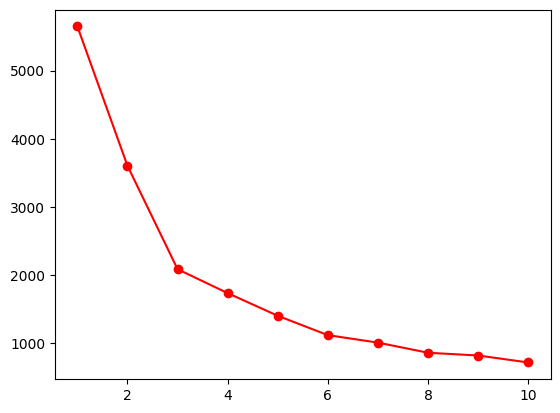

In [14]:
import matplotlib.pyplot as plt

plt.plot(range(1, 11), wcss, 'ro-')
plt.show()

In [15]:
kmeans_model = KMeans(n_clusters=7)
cluster = kmeans_model.fit_predict(scaled_values)

import warnings
warnings.filterwarnings("ignore")

df['Cluster'] = cluster
df

,ORDERLINENUMBER,SALES,Cluster
0,2,2871.00,1
1,5,2765.90,1
2,2,3884.34,4
3,6,3746.70,5
4,14,5205.27,6
...,...,...,...
2818,15,2244.40,0
2819,1,3978.51,4
2820,4,5417.57,4
2821,1,2116.16,1


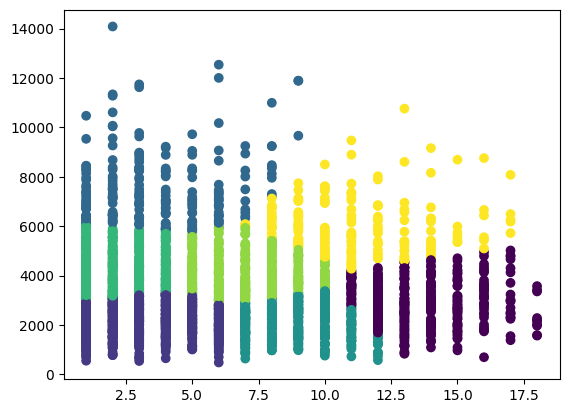

In [16]:
plt.scatter(df['ORDERLINENUMBER'], df['SALES'], c=df['Cluster'])